## Лабораторная 02 — Аугментация данных и устойчивость

**Цель:** Определить, как контролируемые детерминированные изменения волновой (и не только) формы влияют на одну небольшую локальную базовую ASR-модель.

**Выполнила:** Иванова М.К.  
**Проверил:** Романенко А.Н.

### 0. Импорты

In [ ]:
import sys
import librosa
import numpy as np
import pandas as pd
import soundfile as sf
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display

#### Начальные шаги

In [17]:
aug_dir = Path("outputs/augmented")
fig_dir = Path("outputs/figures")

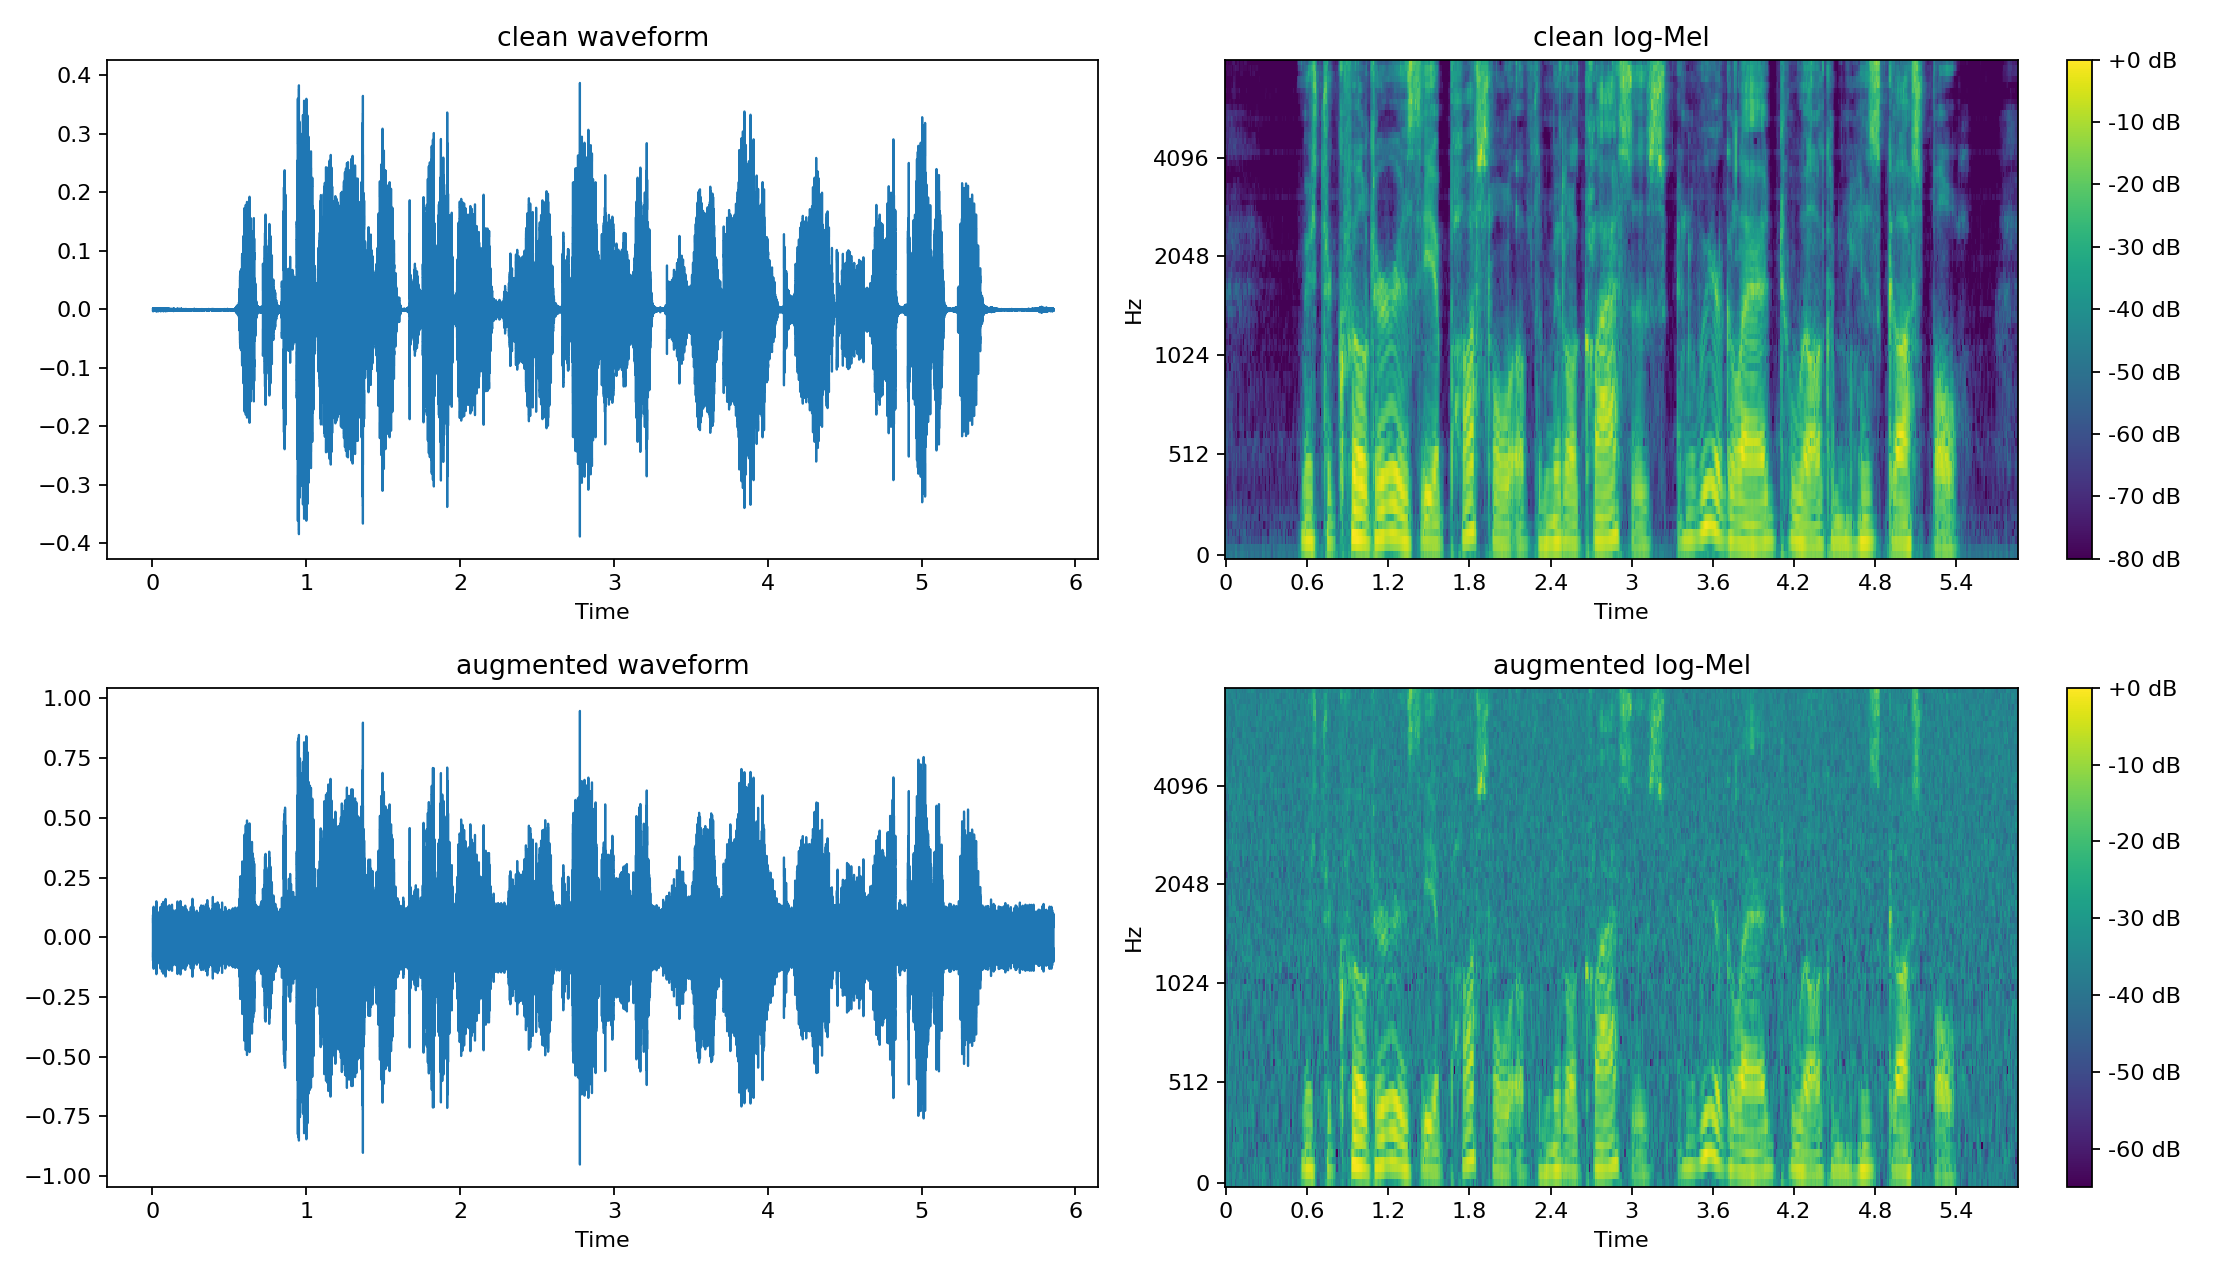

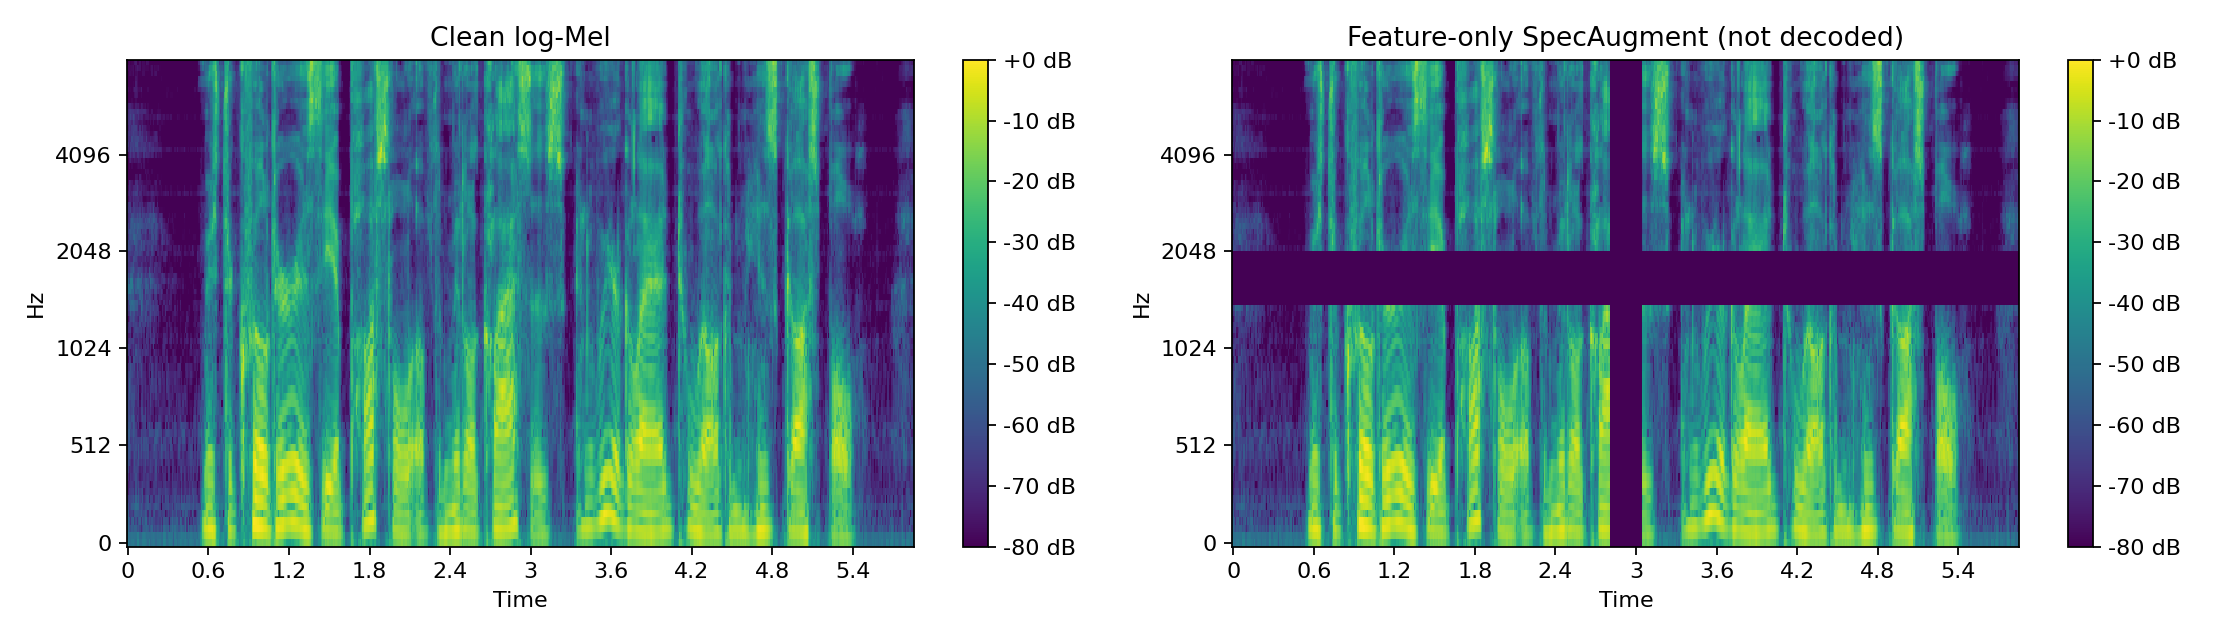

In [ ]:
display(Image(fig_dir / "clean_vs_augmented.png"))
display(Image(fig_dir / "specaugment_feature_only.png"))

На графиках приведены два типа воздействий:
  - clean_vs_augmented.png - зашумление: шум накладывается поверх сигнала, маскируя форманты, но не меняя временную структуру;
  - specaugment_feature_only.png - маскирование признаков: часть log-Mel обнуляется.
Оба варианта при обучении модели повышают ее робастность к частичной потере спектра. Модель учится не полагаться на отдельные моменты времени и частоты, а восстанавливать контекст.

In [3]:
results_dir = Path("outputs/results")
agg = pd.read_csv(results_dir / "aggregate_results.csv")
print("aggregate_results.csv")
display(agg)

aggregate_results.csv


,condition,utterance_count,reference_word_count,mean_wer,mean_cer,mean_rtf
0,clean,5,82,0.103958,0.059503,0.056039
1,noise_0db,5,82,0.654995,0.360833,0.106301
2,noise_10db,5,82,0.165625,0.087189,0.056831
3,noise_20db,5,82,0.128958,0.070029,0.056592
4,reverb_room_a,5,82,0.140625,0.070363,0.057359
5,speed_0.9x,5,82,0.083958,0.047959,0.050371
6,speed_1.1x,5,82,0.087291,0.054097,0.063219


In [4]:
per_item = pd.read_csv(results_dir / "per_item_results.csv")

print("per_item_results.csv")
display(per_item.head(5))

per_item_results.csv


,item_id,condition,parameters,seed,reference_raw,reference_normalized,hypothesis_raw,hypothesis_normalized,wer,cer,audio_seconds,decode_seconds,rtf
0,1272-128104-0000,clean,{},17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.855,0.418875,0.071541
1,1272-128104-0000,noise_20db,"{""snr_db"": 20.0}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.855,0.398840,0.068120
2,1272-128104-0000,noise_10db,"{""snr_db"": 10.0}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.855,0.420153,0.071760
3,1272-128104-0000,noise_0db,"{""snr_db"": 0.0}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Closer is the apostle of the middle classe...,mr closer is the apostle of the middle classes...,0.470588,0.292135,5.855,0.387506,0.066184
4,1272-128104-0000,reverb_room_a,"{""rir"": ""room_a""}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.855,0.404666,0.069115


### 1. Выберите пару аугментаций, и проанализируйте, как они влияют на сигнал (поможет построить графики, подобные clean_vs_augmented.png). Какие два видимые изменения вы наблюдаете в волновой форме и/или log-Mel представлении?

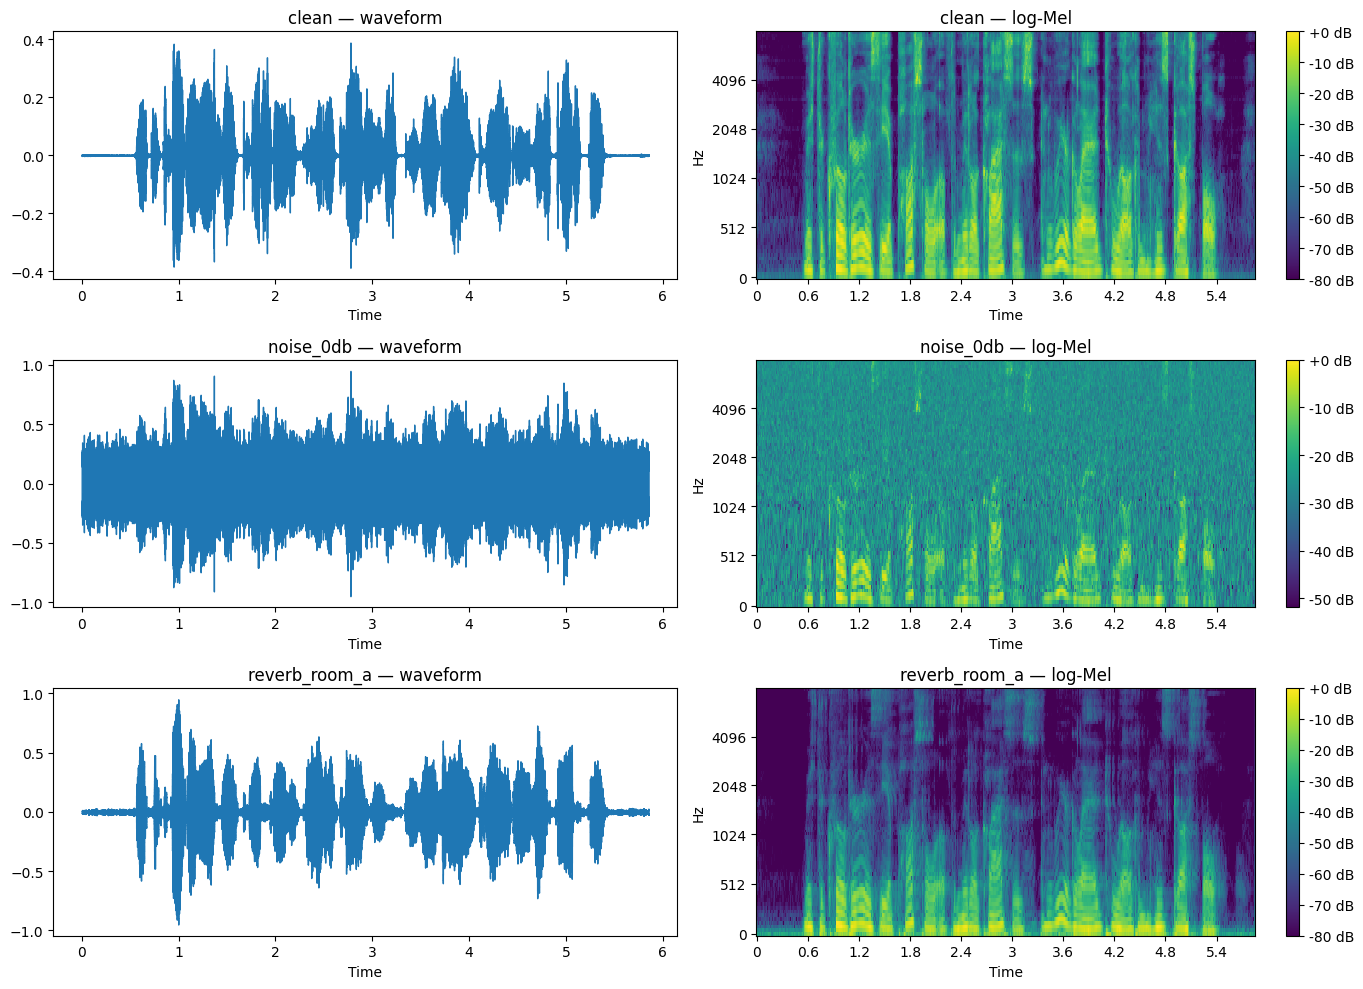

In [ ]:
item = "1272-128104-0000"

files = {
    "clean": aug_dir / f"{item}__clean.wav",
    "noise_0db": aug_dir / f"{item}__noise_0db.wav",
    "reverb_room_a": aug_dir / f"{item}__reverb_room_a.wav",
}

def log_mel(audio: np.ndarray, sample_rate: int) -> np.ndarray:
    mel = librosa.feature.melspectrogram(y=audio, sr=sample_rate, n_fft=400, hop_length=160, win_length=400, n_mels=80, fmin=20, fmax=7600)
    return librosa.power_to_db(mel, ref=np.max)

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for row, (label, path) in enumerate(files.items()):
    y, sr = librosa.load(path, sr=16000, mono=True)
    librosa.display.waveshow(y, sr=sr, ax=axes[row, 0])
    axes[row, 0].set_title(f"{label} — waveform")
    img = librosa.display.specshow(log_mel(y, sr), sr=sr, hop_length=160,
                                   x_axis="time", y_axis="mel",
                                   ax=axes[row, 1], cmap="viridis")
    axes[row, 1].set_title(f"{label} — log-Mel")
    fig.colorbar(img, ax=axes[row, 1], format="%+2.0f dB")

fig.tight_layout()
plt.show()

Пара аугментаций для одного и того же аудио: 
  - аддитивный шум `noise_0db`
  - реверберация `reverb_room_a`

### Два видимых изменения

**1. Аддитивный шум (`noise_0db`).**

- **Waveform:** в сигнале появляются случайные колебания, шум распределяется по всему сигналу, включая  паузы, а его амплитуда сравнима с амплитудой речи. Пики речи уже не  выделяются на фоне шума так чётко, как в чистом сигнале.
- **log-Mel:** появляется равномерный широкополосный фон, форманты становятся неразличимы.  Временная структура не меняется: пики и паузы остаются на своих местах, но замаскированы по амплитуде.

**2. Реверберация (`reverb_room_a`).**

- **Waveform:** после резких пиков происходит постепенное затухание (временная структура становится менее четкой), это затухание продолжается и в паузах.
- **log-Mel:** вертикальные структуры размываются по времени, форманты становятся менее четкими.

| | Шум (`noise_0db`) | Реверберация (`reverb_room_a`) |
|---|---|---|
| Механизм | аддитивное маскирование | свёртка с RIR |
| Waveform | равномерные случайные колебания| затухающие хвосты |
| log-Mel | ровный фон по всем частотам | размытие по времени |

### 2. Сравните аугментацию реверберацией room_a с аугментацией шумом (snr выберете сами). Какое видимое различие согласуется с временным размыванием, а не с простым аддитивным маскированием?

Для сравнения выбрана аугментация `noise_0db` (SNR = 0 - шум очень мощный, эффект максимально заметен) и реверберация
`reverb_room_a`.

С временным размыванием согласуется **наличие затухающих хвостов во времени и горизонтальное размытие атак** у `reverb_room_a`.

Реверберация - **свёртка** сигнала с импульсным откликом помещения. Каждый сэмпл исходного сигнала размывается вперёд и продолжает звучать. Поэтому:

- в waveform огибающая размыта, поэтому визуально подъемы и спады становятся плавнее;
- на log-Mel Вертикальные структуры размыты, границы сегментов смазаны.

В отличие от реверберации, шум накладывается поверх и не переносит существующую энергию во времени. На waveform это видно как равномерное
распределение случайных колебаний без хвостов, на log-Mel - ровный фон без горизонтального размытия.

| Признак | Шум (`noise_0db`) | Реверберация (`reverb_room_a`) |
|---|---|---|
| Механизм | аддитивное маскирование | свёртка с RIR |
| Перенос энергии во времени | нет | да (хвосты после пиков, размытие) |
| В паузах | равномерный шум | затухающий хвост от предыдущего пика |

**Вывод:** с временным размыванием согласуется затухающий хвост после пиков и горизонтальное размытие вертикальных структур у `reverb_room_a`.
Это отличает реверберацию от аддитивного шума, который маскирует по амплитуде, но не меняет временную структуру сигнала.

### 3. Сравните длительности аудио 0.9× и 1.1× с исходыми. Как каждый фактор влияет на длительность и почему одного изменения длительности недостаточно для предсказания как себя поведёт WER?

In [7]:
agg = pd.read_csv("outputs/results/aggregate_results.csv")
agg[agg["condition"].isin(["clean", "speed_0.9x", "speed_1.1x"])][
    ["condition", "mean_wer", "mean_cer", "mean_rtf"]
]

,condition,mean_wer,mean_cer,mean_rtf
0,clean,0.103958,0.059503,0.056039
5,speed_0.9x,0.083958,0.047959,0.050371
6,speed_1.1x,0.087291,0.054097,0.063219


In [8]:
item = "1272-128104-0000"

rows = []
for cond in ["clean", "speed_0.9x", "speed_1.1x"]:
    info = sf.info(aug_dir / f"{item}__{cond}.wav")
    rows.append({"condition": cond, "duration_s": round(info.duration, 3), "samplerate" : (info.samplerate)})

pd.DataFrame(rows)

,condition,duration_s,samplerate
0,clean,5.855,16000
1,speed_0.9x,6.506,16000
2,speed_1.1x,5.323,16000


| Аудио | длительность | изменение длительности относительно clean |
|---|---|---|
| clean | 5.855 | — |
| speed_0.9x | 6.506 | **+11.1 %**|
| speed_1.1x | 5.323 | **−9.1 %**|

То есть замедление удлиняет сигнал, а ускорение укорачивает пропорционально коэффициенту пересэмплирования.

### Почему длительности недостаточно для предсказания WER

Агрегированные метрики по всем 5 примерам:

| аугментация | mean_wer | mean_cer |
|---|---|---|
| clean | 0.1040 | 0.0595 |
| speed_0.9x | 0.0840 | 0.0480 |
| speed_1.1x | 0.0873 | 0.0541 |

Оба варианта продемонстрировали WER лучше, чем `clean`, хотя длительность у них изменилась. Значит, длина сигнала сама по себе не определяет качество распознавания. 

Причины:

1. **Меняется не только длительность, но и спектр.** При растяжении сигнала период увеличивается, следовательно, частоты уменьшаются, значит, звук становится ниже. Аналогично при сжатии сигнала звук становится выше. Поэтому спектр сдвигается вверх или вниз и форманты меняют местоположение. Модель обучалась на  данных LibriSpeech с нормальным темпом; небольшой сдвиг по частоте может повлиять на ее устойчивость.

2. **Разные звуки страдают по-разному.** Для распознавания гласных звуков важны форманты, поэтому для текста с большим количеством гласных WER будет выше, чем для текста той же длины с большим количеством согласных.

3. **Языковая модель декодера.** Если акустика даёт неуверенные гипотезы, LM может додумать частотные фразы. Где-то это может случайно улучшить WER, а где-то ухудшить. Это зависит от уверенности модели в контексте.

4. **Малая выборка** - изменение WER в пределах от 0.084 до 0.104 на малой выборке может быть шумом.

**Вывод:** длительность - только один из факторов. WER зависит ещё от спектральных изменений (сдвиг формант), от того, какие именно слова
произносятся, от предпочтений LM-декодера и от объёма выборки. Поэтому по одной длительности предсказать WER нельзя.

### 4. Какие области скрыты временными и частотными масками в specaugment_feature_only.png? Предположите, почему такая аугментация может быть полезной для обучения систем ASR?

clean_mel.shape = (80, 586)
metadata: {'time_start': 281, 'time_width': 24, 'frequency_start': 35, 'frequency_width': 10}

Time mask:  кадры 281–304 (2.81–3.04 с)
Freq mask:  mel-полосы 35–44 (1399–2055 Гц)


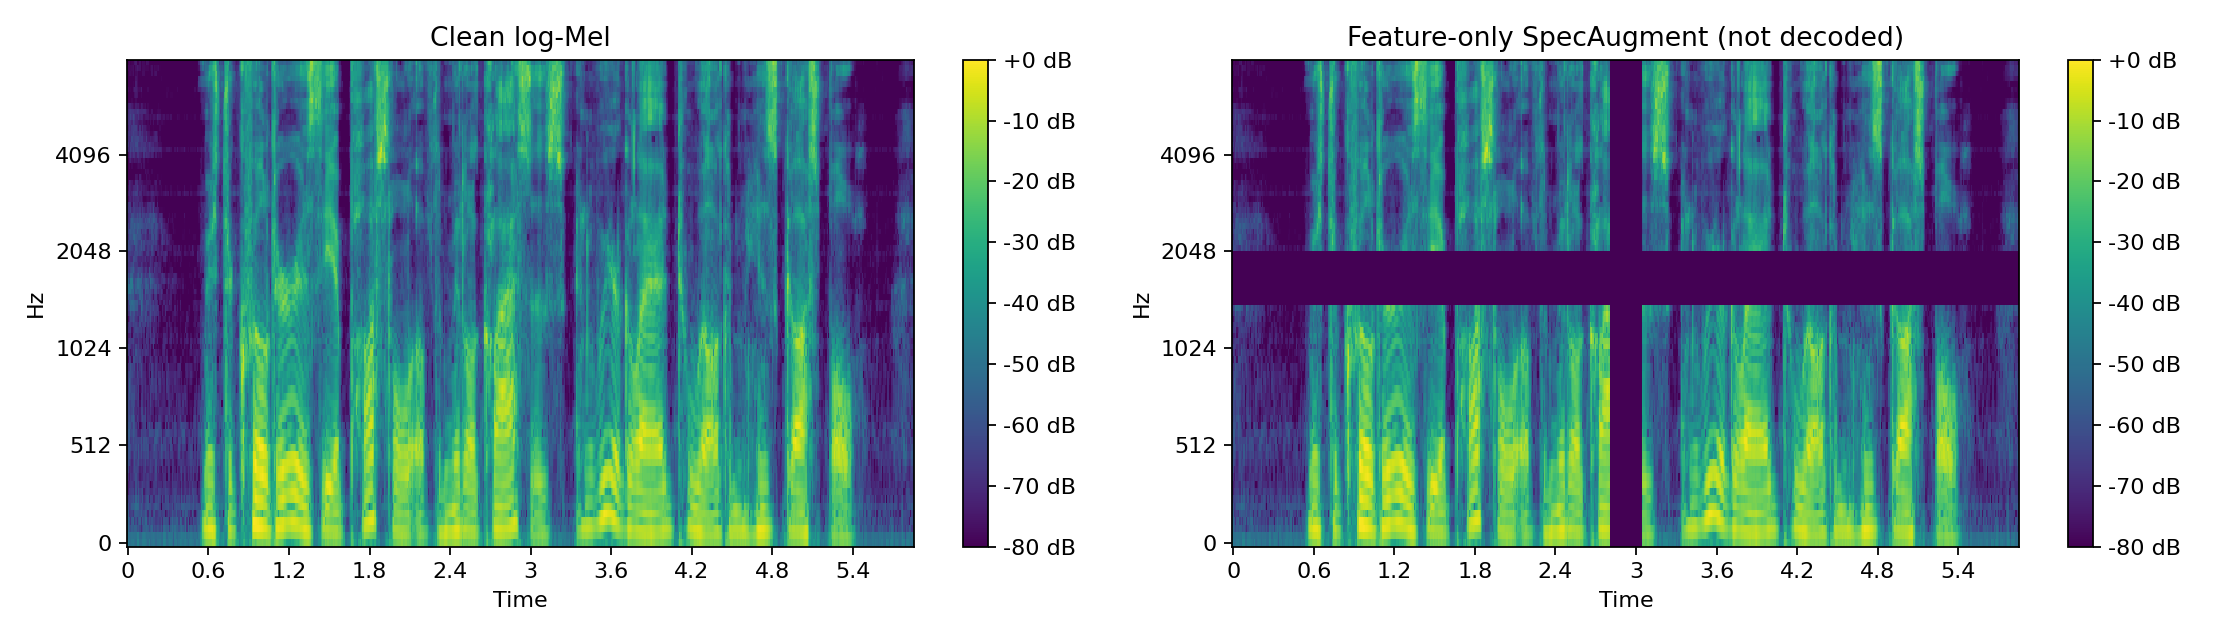

In [9]:
sys.path.append(str(Path("scripts").resolve()))
from plot_augmentation_features import log_mel, specaugment

clean, sr = librosa.load("data/wav/1272-128104-0000.wav", sr=16000, mono=True)
clean_mel = log_mel(clean, sr)
masked, meta = specaugment(clean_mel)

print("clean_mel.shape =", clean_mel.shape)
print("metadata:", meta)

time_start = meta["time_start"]
time_width = meta["time_width"]
freq_start = meta["frequency_start"]
freq_width = meta["frequency_width"]

time_frames = list(range(time_start, time_start + time_width))
freq_bands = list(range(freq_start, freq_start + freq_width))

hop_length = 160
time_seconds = [f * hop_length / sr for f in time_frames]

freqs = librosa.mel_frequencies(n_mels=clean_mel.shape[0], fmin=20, fmax=7600)
freq_hz_lo = freqs[freq_start]
freq_hz_hi = freqs[freq_start + freq_width]

print()
print(f"Time mask:  кадры {time_start}–{time_start + time_width - 1} "
      f"({time_seconds[0]:.2f}–{time_seconds[-1]:.2f} с)")
print(f"Freq mask:  mel-полосы {freq_start}–{freq_start + freq_width - 1} "
      f"({freq_hz_lo:.0f}–{freq_hz_hi:.0f} Гц)")

display(Image(fig_dir / "specaugment_feature_only.png"))

- **Временная маска:** кадры 281–304, ширина 24 кадра. Это 2.81–3.04 с. - середина фразы (обычно наиболее информативная средняя часть, поскольку начало и конец фразы часто заполнены паузами и тишиной).
- **Частотная маска:** маскированы mel-полосы 35–44, ширина 10 полос. Это 1399–2055 Гц - средняя часть речевого диапазона.

В замаскированных областях значение устанавливается в минимальное. Появляются две полосы: вертикальная полоса по времени (24 кадра) и горизонтальная по частоте (10 mel-полос). Маски применяются к log-Mel, а не к исходному аудио.

1. **Временная маска** учит модель не полагаться на конкретные моменты времени. Если часть слова неразборчива, модель должна
   восстановить её по контексту (по соседним кадрам).

2. **Частотная маска** учит модель не полагаться на отдельные частотные полосы. Если часть спектра потеряна, модель должна опираться на оставшиеся частоты. Это делает её устойчивее к каналу и микрофону.

**Вывод:** SpecAugment имитирует реальные искажения: пропадание фрагментов речи во времени и потерю части спектра, маскирует середину по времени (24 кадра, 2.8–3.0 с.) и среднюю часть по частоте (10 mel-полос, 1400–2055 Гц). Это регуляризация, повышающая устойчивость ASR к временным и спектральным потерям.


### 5. Для одного тестового примера сравните результаты распознавания чистого сигнала с результатами двух его аугментированных вариантов. Укажите WER, CER и RTF для всех трёх аудио. Какая метрика изменяется сильнее всего в выбранном сравнении? Как думаете, почему?

In [10]:
per_item = pd.read_csv("outputs/results/per_item_results.csv")
item = "1272-128104-0000"

sel = per_item[
    (per_item["item_id"] == item) &
    (per_item["condition"].isin(["clean", "noise_0db", "reverb_room_a"]))
][["condition", "reference_normalized", "hypothesis_normalized",
   "wer", "cer", "rtf"]]

sel

,condition,reference_normalized,hypothesis_normalized,wer,cer,rtf
0,clean,mister quilter is the apostle of the middle cl...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,0.071541
3,noise_0db,mister quilter is the apostle of the middle cl...,mr closer is the apostle of the middle classes...,0.470588,0.292135,0.066184
4,reverb_room_a,mister quilter is the apostle of the middle cl...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,0.069115


| condition | WER | CER | RTF |
|---|---|---|---|
| clean | 0.0588 | 0.0449 | 0.0715 |
| noise_0db | **0.4706** | **0.2921** | 0.0662 |
| reverb_room_a | 0.0588 | 0.0449 | 0.0691 |

- **clean и reverb_room_a дали одинаковый результат.**
  WER = 0.0588, CER = 0.0449. На этом примере реверберация не ухудшила распознавание.
- **noise_0db резко ухудшил метрики.** WER вырос в 8 раз  (с 0.0588 до 0.4706), CER в 6.5 раз (с 0.0449 до 0.2921).
- **RTF почти не изменился** (0.066–0.072). Скорость декодирования практически не зависит от типа аугментации.

Ожидаемо, сильнее других изменилась метрика **WER.** 

  - WER считает **слова целиком**: при каждой ошибке (замена, удаление или вставка) +1 к числителю (S + D + I) при расчете WER.
  - CER считает **символы**: даже в неправильном слове часть символов может совпасть (метрика мягче). Поэтому CER растёт медленнее.

**Вывод:** в выбранном сравнении сильнее всего изменился **WER** (в 8 раз), потому что сильный шум вызывает грубые ошибки на уровне слов, а CER сглаживает их за счёт посимвольного совпадения.

### 6. Определите вариант аугментации с наибольшим агрегированным mean_wer в aggregate_results.csv. Укажите его имя, агрегированные mean_wer, mean_cer и сравнение текстовок для одного тестового примера с этой аугментацией. Как вы думаете, почему такая аугментация сильнее всего сказывается на работе ASR модели?

In [ ]:
agg = pd.read_csv("outputs/results/aggregate_results.csv")
worst = agg.loc[agg["mean_wer"].idxmax()]
clean = agg.loc[agg["condition"] == "clean"].iloc[0]

comparison = pd.DataFrame([clean, worst])[["condition", "mean_wer", "mean_cer", "mean_rtf"]]
comparison

,condition,mean_wer,mean_cer,mean_rtf
0,clean,0.103958,0.059503,0.056039
1,noise_0db,0.654995,0.360833,0.106301


In [ ]:
per_item = pd.read_csv("outputs/results/per_item_results.csv")

for cond in ["clean", "noise_0db"]:
    row = per_item[
        (per_item["item_id"] == "1272-128104-0000") &
        (per_item["condition"] == cond)
    ].iloc[0]
    print(f"{cond}")
    print("Эталон:", row["reference_normalized"])
    print("Текстовка:", row["hypothesis_normalized"])
    print(f"WER = {row['wer']}, CER = {row['cer']}, RTF = {row['rtf']}")
    print()

clean
Эталон: mister quilter is the apostle of the middle classes and we are glad to welcome his gospel
Текстовка: mr quilter is the apostle of the middle classes and we are glad to welcome his gospel
WER = 0.058824, CER = 0.044944, RTF = 0.071541

noise_0db
Эталон: mister quilter is the apostle of the middle classes and we are glad to welcome his gospel
Текстовка: mr closer is the apostle of the middle classes and he has led to the ultimate whose gospel
WER = 0.470588, CER = 0.292135, RTF = 0.066184



Из `aggregate_results.csv` максимум `mean_wer` у **`noise_0db`** (SNR = 0 дБ, шум по мощности сравним с сигналом):

| condition | mean_wer | mean_cer | mean_rtf |
|---|---|---|---|
| clean | 0.1040 | 0.0595| 0.0560 |
| noise_0db | 0.6550 | 0.3608 | 0.1063 |

Шум при SNR = 0 дБ ухудшает WER в 6.3 раза относительно чистого сигнала.

### Сравнение текстовок (для `1272-128104-0000`)

**Эталон:**

> `mister quilter is the apostle of the middle classes and we are glad to welcome his gospel`

**Текстовка модели при аугментации шумом `noise_0db`:**

> `mr closer is the apostle of the middle classes and he has led to the ultimate whose gospel`

**Ошибки:**

- mister на mr - замена (ошибка не акустическая (поскольку оба слова означают одно и то же, а модель, скорее всего, просто выбрала олее частотный вариант), но все равно идет в подсчет WER);
- quilter на closer - замена;
- we are glad to welcome his на he has led to the ultimate whose - целая фраза неверно интерпретирована.

Для этого примера: WER = 0.4706, CER = 0.2921, RTF = 0.0662.

### `noise_0db` сильнее всего сказывается на ASR поскольку:

  - **SNR = 0 дБ**, то есть мощность шума равна мощности речи. Форманты неразличимы в шуме, и модель не может выделить акустические признаки фонем.
  - **Малый размер модели.** У неё ограниченная способность к денойзингу, она не может выделить речь из такого шума, как это делают большие модели.
  - **Ошибки кластерные.** Шум ломает не отдельные слова, а целые фразы. В выбранном примере целая фраза заменена на бессмысленную
   последовательность `he has led to the ultimate whose`. При сильном шуме контекст теряется.

**Вывод:** `noise_0db` - самая агрессивная аугментация среди предложенных. При SNR = 0 дБ мощность шума равна мощности речи, форманты
маскируются, и модель не справляется с денойзингом. Это приводит к `mean_wer = 0.655`, что в 6.3 раза хуже, чем на чистом сигнале.

### 7. Найдите такой тип аугментации, для которого WER и CER сигнализируют о разном уровне влияния на систему ASR (скажем WER деградирует значительно, но CER увеличивается не очень сильно). Рассмотрите текстовки, предположите, почему наблюдается такое поведение?.

In [ ]:
agg = pd.read_csv("outputs/results/aggregate_results.csv")
agg["wer_cer_ratio"] = agg["mean_wer"] / agg["mean_cer"]
agg[["condition", "mean_wer", "mean_cer", "wer_cer_ratio"]].sort_values(
    "wer_cer_ratio", ascending=False
)

,condition,mean_wer,mean_cer,wer_cer_ratio
4,reverb_room_a,0.140625,0.070363,1.998565
2,noise_10db,0.165625,0.087189,1.899609
3,noise_20db,0.128958,0.070029,1.841494
1,noise_0db,0.654995,0.360833,1.815230
5,speed_0.9x,0.083958,0.047959,1.750620
0,clean,0.103958,0.059503,1.747105
6,speed_1.1x,0.087291,0.054097,1.613601


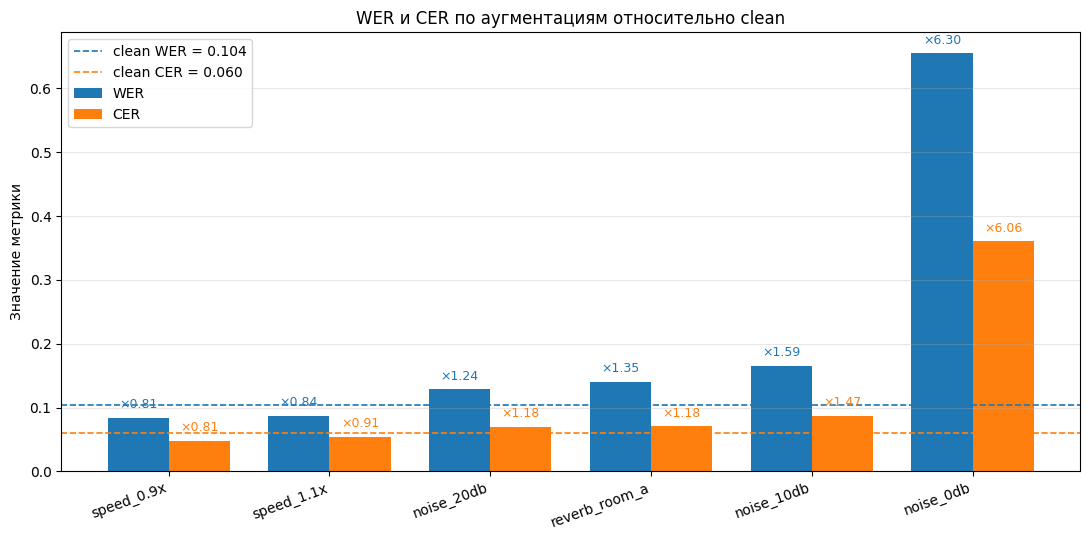

In [ ]:
agg = pd.read_csv("outputs/results/aggregate_results.csv")

clean_wer = agg.loc[agg["condition"] == "clean", "mean_wer"].iloc[0]
clean_cer = agg.loc[agg["condition"] == "clean", "mean_cer"].iloc[0]

plot_df = agg[agg["condition"] != "clean"].sort_values("mean_wer", ascending=True).reset_index(drop=True)

plot_df["wer_growth"] = plot_df["mean_wer"] / clean_wer
plot_df["cer_growth"] = plot_df["mean_cer"] / clean_cer

x = np.arange(len(plot_df))
width = 0.38

fig, ax = plt.subplots(figsize=(11, 5.5))

bars_wer = ax.bar(x - width/2, plot_df["mean_wer"], width, label="WER")
bars_cer = ax.bar(x + width/2, plot_df["mean_cer"], width, label="CER")

ax.axhline(clean_wer, color="C0", linestyle="--", linewidth=1.2, label=f"clean WER = {clean_wer:.3f}")
ax.axhline(clean_cer, color="C1", linestyle="--", linewidth=1.2, label=f"clean CER = {clean_cer:.3f}")

for bar, growth in zip(bars_wer, plot_df["wer_growth"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"×{growth:.2f}", ha="center", va="bottom", fontsize=9, color="C0")

for bar, growth in zip(bars_cer, plot_df["cer_growth"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"×{growth:.2f}", ha="center", va="bottom", fontsize=9, color="C1")

ax.set_xticks(x)
ax.set_xticklabels(plot_df["condition"], rotation=20, ha="right")
ax.set_ylabel("Значение метрики")
ax.set_title("WER и CER по аугментациям относительно clean")
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Если WER и CER растут пропорционально, их отношение не меняется. Расхождение видно там, где WER-прирост заметно больше CER-прироста.

| condition | WER, % от clean | CER, % от clean | разрыв (WER − CER) |
|---|---|---|---|
| speed_0.9x | 81 % | 81 % | 0 |
| speed_1.1x | 84 % | 91 % | −7 |
| noise_20db | 124 % | 118 % | 6 |
| **reverb_room_a** | **135 %** | **118 %** | **17** |
| noise_10db | 159 % | 147 % | 12 |
| noise_0db | 630 % | 606 % | 24 |

Самый большой **разрыв между приростами** наблюдается у `reverb_room_a`: WER вырос на 35%, а CER на 18 % относительно `clean`. То есть WER и CER отражают разный уровень влияния реверберации на ASR.

### Причины

1. **WER считает слова целиком.** Реверберация размывает границы фонем и слов; LM-декодер чаще ошибается на уровне слов, заменяя
   одно слово на похожее по звучанию/контексту.
2. **CER считает символы.** Даже если слово заменено, внутри него часть символов совпадает. Форманты при реверберации только размываются, и большая часть символов распознается верно.

**Вывод:** расхождение WER и CER максимально у `reverb_room_a`: WER растёт в 1.35 раза, а CER только в 1.18. Это происходит
потому, что реверберация меняет границы слов, но внутри слов большая часть символов распознаётся.

### 8. Для идентичной ошибки/ошибок распознавания при разных типах аугментации приведите эталон и гипотезу (или их фрагменты). Является ли правдоподобным объяснением акустическое маскирование, временное размывание, сегментация/тайминг или предпочтение декодера/языковой модели? Укажите, какие у вас есть предположения, относительно таких ошибок распознавания.

In [ ]:
per_item = pd.read_csv("outputs/results/per_item_results.csv")

pivot = per_item.pivot_table(
    index="item_id", columns="condition", values="wer"
)

for item, row in pivot.iterrows():
    if pd.isna(row["clean"]):
        continue
    matches = [c for c in pivot.columns if c != "clean" and row[c] == row["clean"]]
    if matches:
        print(f"{item}: clean WER = {row['clean']:.4f}, совпадает с {matches}")

1272-128104-0000: clean WER = 0.0588, совпадает с ['noise_10db', 'noise_20db', 'reverb_room_a', 'speed_0.9x', 'speed_1.1x']
1272-128104-0001: clean WER = 0.2000, совпадает с ['noise_20db', 'speed_1.1x']
1272-128104-0003: clean WER = 0.0417, совпадает с ['speed_0.9x', 'speed_1.1x']
1272-128104-0006: clean WER = 0.1667, совпадает с ['noise_20db', 'reverb_room_a', 'speed_0.9x']
1272-128104-0007: clean WER = 0.0526, совпадает с ['noise_10db', 'noise_20db', 'reverb_room_a', 'speed_0.9x', 'speed_1.1x']


In [ ]:
item = "1272-128104-0003"
sel = per_item[per_item["item_id"] == item][
    ["condition", "reference_normalized", "hypothesis_normalized", "wer"]
]
pd.set_option("display.max_colwidth", None)
sel

,condition,reference_normalized,hypothesis_normalized,wer
14,clean,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca,0.041667
15,noise_20db,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has great doubts whether sir frederick layton's work is really greek after all and can discover in it but little of wonky ichaka,0.166667
16,noise_10db,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has great doubts whether sir frederick leighton's work is really great after all and can discover in it but little of wonky essica,0.166667
17,noise_0db,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has great notes for that so he's going to make him work with me he's beat after all and he can discover in it a little while he isn't hurt,0.833333
18,reverb_room_a,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of wonky ithaka,0.125000
19,speed_0.9x,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca,0.041667
20,speed_1.1x,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca,0.041667


Эталон:

> `he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca`

**Одинаковая ошибка при четырёх разных аугментациях:**

| condition | гипотеза модели | WER |
|---|---|---|
| clean | `...sir frederick layton's work...` | 0.0417 |
| reverb_room_a | `...sir frederick layton's work...` | 0.1250 |
| speed_0.9x | `...sir frederick layton's work...` | 0.0417 |
| speed_1.1x | `...sir frederick layton's work...` | 0.0417 |

Во всех случаях модель заменяет `leighton's` на `layton's`.

| Гипотеза | Правдоподобна ли | Объяснение |
|---|---|---|
| Акустическое маскирование | Нет | Ошибка есть и в `clean`, где нет шума |
| Временное размывание | Нет | Ошибка есть в `clean`, где нет реверберации |
| Сегментация/тайминг | Нет | Границы слов не сдвинуты |
| Предпочтение декодера / LM | Да | `Leighton` и `Layton` - омофоны, LM выбирает частотное |

`Leighton` и `Layton` произносятся одинаково. Акустически модель не может их различить по звучанию. Выбор делается в пользу более частотного слова. `Layton`, судя по всему, - более распространённая фамилия, чем `Leighton`.

А при сильном шуме (`noise_0db`) добавляются уже настоящие **акустические** ошибки (`grave` - `great`, `doubts` - `notes` и др.).

**Вывод:** идентичная ошибка (замена `leighton's` на `layton's`) при разных аугментациях объясняется **предпочтением LM-декодера**, а не
акустическим маскированием или временным размыванием. Это **лексическая** ошибка: модель слышит омофон и выбирает более частотное написание.

### 9. Как вы думаете, всегда ли более высокий WER в нашем бенчмарке, есть индикатор того, что такая аугментация - универсальная ASR? Назовите два фактора в этой лабораторной работе, которые не позволяют сделать такой вывод.

Высокий WER в этом бенчмарке означает только, что данная модель плохо справилась с конкретным набором данных. Делать вывод об
универсальной сложности аугментации для ASR в целом нельзя.

### Два возможных фактора:

1. **Маленькая модель `tiny.en`.** Это самая компактная версия Whisper. Аугментация, которая её ломает, может быть безвредна
   для больших моделей. То есть WER, полученный на `tiny.en`, не переносится на другие модели и не описывает сложность аугментации в целом.

2. **Маленькая выборка.** В наборе всего 5 аудио в эталонах. Разница `mean_wer` между условиями может быть шумом, а не эффектом аугментации. Например, `speed_0.9x` показал WER лучше clean, но на 5 примерах это может быть случайностью, а не свойством аугментации.

3. Все аугментации в примерах **детерминированы**. Все варианты шума/реверберации/скорости зафиксированы. Это тоже ограничивает
обобщение.

**Вывод:** высокий WER в этих примерах указывает на сложность аугментации для конкретной модели `tiny.en` на конкретном наборе из
5 примеров. Обобщать этот результат для ASR нельзя: ни по модели, ни по объёму выборки, ни по разнообразию условий.